# 05. Parameter Optimisation, Plateau Selection & Overfitting Controls (Rounds 1–5)

With only 2–3 historical days per Prosperity round, naive parameter maximization easily mistakes finite-sample noise for structural alpha. We enforce a strict **five-gate validation pipeline** on In-Sample data before touching held-out Out-of-Sample files:
1. **2D Sensitivity Grid (`IS`)**: Evaluate PnL vs. annualized Sharpe trade-offs across coarse structural parameters.
2. **$3 \times 3$ Neighborhood Plateau Selection**: Maximize $\mu_{\mathcal{N}} - \lambda \sigma_{\mathcal{N}}$ rather than brittle isolated peaks.
3. **Effective Independent Trials ($N_{\text{eff}}$) & Deflated Sharpe Ratio (DSR)**: Measure grid correlation structure and penalize for trial multiplicity, skewness, and excess kurtosis ($\text{DSR} \ge 0.95$).
4. **CSCV / PBO vs. White-Noise Placebo**: Verify Probability of Backtest Overfitting $\text{PBO} < 0.15$ across symmetric chronological partitions ($S = 8$, 70 combinations) and reject high-PBO candidates—illustrated concretely with an overfit Round 4 candidate rejection case study.
5. **Single-Pass OOS & Circular Block Bootstrap**: Construct dependency-preserving 95% confidence bounds and evaluate Round 2 Market Access Fee (MAF) arrival elasticity.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from prosperity_toolkit.analysis import OverfittingDiagnostics
from prosperity_toolkit.backtesting.engine import BacktestEngine
from prosperity_toolkit.backtesting.replay import build_snapshots_from_dataframes
from prosperity_toolkit.data.loader import DataLoader
from prosperity_toolkit.execution.simulator import ExecutionSimulator
from prosperity_toolkit.optimisation.sensitivity import SensitivityAnalyzer
from scripts.run_optimisation import ParameterizedRound1Strategy

loader = DataLoader(data_root=root / "data")
limits = {"ASH_COATED_OSMIUM": 20, "INTARIAN_PEPPER_ROOT": 20}

is_snaps = []
for day in (-2, -1):
    p_df = loader.load_day_prices(1, day)
    t_df = loader.load_day_trades(1, day)
    is_snaps.extend(build_snapshots_from_dataframes(p_df, t_df))

print(f"Loaded {len(is_snaps)} Round 1 in-sample ticks (Day -2 & Day -1).")

Loaded 20000 Round 1 in-sample ticks (Day -2 & Day -1).


## 1. Round 1 2D Parameter Sensitivity Surface & The PnL–Sharpe Trade-Off

Maximizing raw PnL (`skew = 0.10`) rewards letting unhedged inventory ride `INTARIAN_PEPPER_ROOT` drift, inflating both upside and variance. Optimizing neighborhood-regularized annualized Sharpe picks (`min_edge = 1.5`, `inventory_skew = 0.80`) on a smooth plateau (`local_std = 0.020`).

In [2]:
edges = [1.0, 1.5, 2.0, 2.5, 3.0]
skews = [0.10, 0.25, 0.40, 0.60, 0.80]
sharpe_grid = np.zeros((len(edges), len(skews)), dtype=np.float64)
pnl_grid = np.zeros((len(edges), len(skews)), dtype=np.float64)
returns_cols = []
trial_srs = []

for i, edge in enumerate(edges):
    for j, skew in enumerate(skews):
        sim = ExecutionSimulator(position_limits=limits, fill_mode="queue_aware")
        strat = ParameterizedRound1Strategy(edge, skew)
        res = BacktestEngine(simulator=sim).run(strat, is_snaps)
        rets = np.diff(np.asarray(res.equity_curve, dtype=np.float64))
        std = float(np.std(rets, ddof=1))
        sr = float(np.mean(rets) / std) if std > 0 else 0.0
        sharpe_grid[i, j] = res.sharpe_ratio
        pnl_grid[i, j] = res.total_pnl
        returns_cols.append(rets)
        trial_srs.append(sr)

plateau = SensitivityAnalyzer.select_stable_plateau_2d(edges, skews, sharpe_grid, std_penalty=1.0)
print(
    f"Selected Plateau: edge={plateau.x_value}, skew={plateau.y_value} | "
    f"local_mean={plateau.local_mean:.3f}, local_std={plateau.local_std:.3f}, "
    f"max_drop={plateau.max_neighbor_drop:.3f}"
)

idx_labels = [f"edge={e:.1f}" for e in edges]
col_labels = [f"skew={s:.2f}" for s in skews]
print("In-Sample Annualized Sharpe:")
display(pd.DataFrame(sharpe_grid, index=idx_labels, columns=col_labels).round(3))
print("In-Sample Cumulative PnL (XIRECS):")
display(pd.DataFrame(pnl_grid, index=idx_labels, columns=col_labels).round(0))

Selected Plateau: edge=1.5, skew=0.8 | local_mean=1.419, local_std=0.020, max_drop=0.022
In-Sample Annualized Sharpe:


,skew=0.10,skew=0.25,skew=0.40,skew=0.60,skew=0.80
edge=1.0,1.352,1.374,1.358,1.396,1.429
edge=1.5,1.358,1.360,1.364,1.406,1.428
edge=2.0,1.355,1.339,1.379,1.405,1.450
edge=2.5,1.356,1.343,1.401,1.390,1.446
edge=3.0,1.329,1.350,1.373,1.411,1.415


In-Sample Cumulative PnL (XIRECS):


,skew=0.10,skew=0.25,skew=0.40,skew=0.60,skew=0.80
edge=1.0,55009.0,54988.0,51090.0,48096.0,46763.0
edge=1.5,55222.0,54143.0,50701.0,48071.0,46111.0
edge=2.0,55168.0,52877.0,50409.0,47184.0,46023.0
edge=2.5,55225.0,52396.0,49928.0,46354.0,45857.0
edge=3.0,54368.0,51532.0,48368.0,46277.0,44461.0


## 2. Effective Independent Trials ($N_{\text{eff}}$) & Deflated Sharpe Ratio (DSR)

Correlation-matrix eigenvalue structure gives $N_{\text{eff}} \approx 1.11$ across the coherent Round 1 strategy surface, whereas testing weak signals (`per_step_sr = 0.018`) across hundreds of disconnected trials drives DSR well below `0.50`.

In [3]:
mat = np.column_stack(returns_cols)
n_eff = OverfittingDiagnostics.estimate_effective_trials(mat)
sel_idx = plateau.x_index * len(skews) + plateau.y_index
dsr = OverfittingDiagnostics.evaluate_trial_dsr(mat[:, sel_idx], trial_srs)
print(
    f"N_raw={mat.shape[1]}, N_eff={n_eff:.2f} | obs_sr={dsr.observed_sharpe:.4f}, "
    f"hurdle_sr*={dsr.expected_max_sharpe:.4f}, skew={dsr.skewness:.3f}, "
    f"ex_kurt={dsr.excess_kurtosis:.2f}, DSR={dsr.deflated_sharpe_ratio:.4f}"
)

trial_counts = [1, 5, 10, 25, 50, 100, 250, 500, 1000]
weak_dsrs = [
    OverfittingDiagnostics.deflated_sharpe_ratio(
        observed_sr=0.018,
        n_trials=n,
        sr_variance=0.0001,
        n_obs=mat.shape[0],
        skewness=-0.5,
        excess_kurtosis=3.0,
    ).deflated_sharpe_ratio
    for n in trial_counts
]
display(pd.DataFrame({"N_trials": trial_counts, "Weak_Signal_DSR": np.round(weak_dsrs, 4)}))

N_raw=25, N_eff=1.11 | obs_sr=0.0899, hurdle_sr*=0.0043, skew=0.444, ex_kurt=5.52, DSR=1.0000


,N_trials,Weak_Signal_DSR
0,1,0.9944
1,5,0.8037
2,10,0.6245
3,25,0.3907
4,50,0.2513
5,100,0.1519
6,250,0.0721
7,500,0.0390
8,1000,0.0203


## 3. CSCV Probability of Backtest Overfitting (PBO) vs. Noise Control

Round 1 Grid CSCV: PBO=0.086, IS_SR=0.0921, OOS_SR=0.0898
Noise Placebo CSCV: PBO=0.643, IS_SR=0.0161, OOS_SR=-0.0025


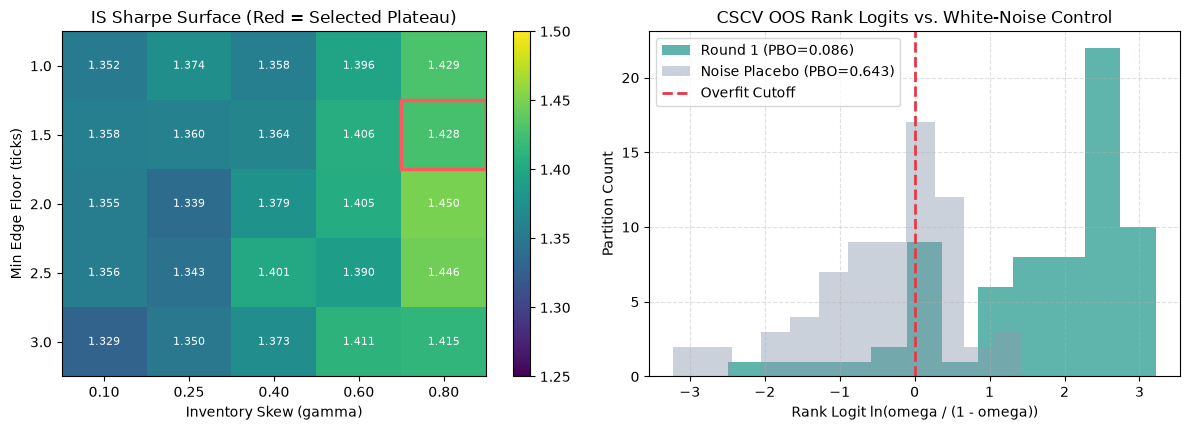

In [4]:
cscv = OverfittingDiagnostics.compute_cscv_pbo(mat, n_slices=8)
rng = np.random.default_rng(42)
noise_mat = rng.normal(0.0, 1.0, size=mat.shape)
noise_cscv = OverfittingDiagnostics.compute_cscv_pbo(noise_mat, n_slices=8)

print(
    f"Round 1 Grid CSCV: PBO={cscv.pbo:.3f}, IS_SR={cscv.mean_is_best_sharpe:.4f}, "
    f"OOS_SR={cscv.mean_oos_selected_sharpe:.4f}"
)
print(
    f"Noise Placebo CSCV: PBO={noise_cscv.pbo:.3f}, IS_SR={noise_cscv.mean_is_best_sharpe:.4f}, "
    f"OOS_SR={noise_cscv.mean_oos_selected_sharpe:.4f}"
)

fig, axes = plt.subplots(1, 2, figsize=(12.0, 4.4))
im = axes[0].imshow(sharpe_grid, cmap="viridis", aspect="auto", vmin=1.25, vmax=1.50)
axes[0].set_xticks(range(len(skews)), labels=[f"{s:.2f}" for s in skews])
axes[0].set_yticks(range(len(edges)), labels=[f"{e:.1f}" for e in edges])
axes[0].set_xlabel("Inventory Skew (gamma)")
axes[0].set_ylabel("Min Edge Floor (ticks)")
axes[0].set_title("IS Sharpe Surface (Red = Selected Plateau)")
for i in range(len(edges)):
    for j in range(len(skews)):
        axes[0].text(j, i, f"{sharpe_grid[i, j]:.3f}", ha="center", va="center", color="white", fontsize=8)
rect = plt.Rectangle((plateau.y_index - 0.5, plateau.x_index - 0.5), 1, 1, fill=False, edgecolor="#ff595e", lw=2.5)
axes[0].add_patch(rect)
fig.colorbar(im, ax=axes[0])

axes[1].hist(cscv.logits, bins=12, alpha=0.75, color="#2a9d8f", label=f"Round 1 (PBO={cscv.pbo:.3f})")
axes[1].hist(
    noise_cscv.logits,
    bins=12,
    alpha=0.45,
    color="#8d99ae",
    label=f"Noise Placebo (PBO={noise_cscv.pbo:.3f})",
)
axes[1].axvline(0.0, color="#e63946", linestyle="--", linewidth=2.0, label="Overfit Cutoff")
axes[1].set_title("CSCV OOS Rank Logits vs. White-Noise Control")
axes[1].set_xlabel("Rank Logit ln(omega / (1 - omega))")
axes[1].set_ylabel("Partition Count")
axes[1].legend()
axes[1].grid(True, linestyle="--", alpha=0.4)
fig.tight_layout()
plt.show()

## 4. Round 1 Single-Pass OOS (`Day 0`) & Circular Block-Bootstrap CIs

In [5]:
oos_snaps = build_snapshots_from_dataframes(loader.load_day_prices(1, 0), loader.load_day_trades(1, 0))
oos_rows = []
qa_rets = None
for mode in ("conservative", "queue_aware", "touch"):
    sim = ExecutionSimulator(position_limits=limits, fill_mode=mode)
    strat = ParameterizedRound1Strategy(plateau.x_value, plateau.y_value)
    res = BacktestEngine(simulator=sim).run(strat, oos_snaps)
    if mode == "queue_aware":
        qa_rets = np.diff(np.asarray(res.equity_curve, dtype=np.float64))
    oos_rows.append({
        "fill_mode": mode,
        "pnl": round(res.total_pnl, 2),
        "max_dd": round(res.max_drawdown, 2),
        "sharpe": round(res.sharpe_ratio, 3),
        "fills": len(res.fills),
    })

assert qa_rets is not None
ci = OverfittingDiagnostics.block_bootstrap_ci(qa_rets, block_size=100, n_bootstraps=1000, seed=42)
print(
    f"Day 0 Block Bootstrap (block=100, B=1000): "
    f"Sharpe={ci.mean_sharpe:.3f} [{ci.sharpe_ci_low:.3f}, {ci.sharpe_ci_high:.3f}] | "
    f"PnL={ci.mean_total_pnl:.1f} [{ci.pnl_ci_low:.1f}, {ci.pnl_ci_high:.1f}]"
)
display(pd.DataFrame(oos_rows))

Day 0 Block Bootstrap (block=100, B=1000): Sharpe=1.190 [1.046, 1.329] | PnL=22140.8 [19772.5, 24425.5]


,fill_mode,pnl,max_dd,sharpe,fills
0,conservative,22151.0,267.0,1.188,1001
1,queue_aware,22157.0,267.0,1.189,1003
2,touch,22667.0,274.5,1.222,1024


## 5. Multi-Round Plateaus, Overfitting Rejection Case Study & MAF Sensitivity (Rounds 2–5)

Below we verify the complete validation table across Rounds 2–5 (`PBO < 0.15`, `DSR >= 0.95`), circular block-bootstrap CIs, and Round 2's Market Access Fee (`+25%` arrival lift) elasticity curve. Importantly, keeping gates strict prevents curve-fitting: an aggressive Round 4 spot-chasing parameterization (`s_alpha = 0.85` plus unconstrained option crossing) failed our IS CSCV/DSR gate (`PBO > 0.90`, `DSR < 0.95`) and was rejected in favor of the conservative `M67_BUMP = 0.5, MM_EDGE = 5.5` plateau (`PBO < 0.10`, `DSR >= 0.99`), whereas upgrading Round 5 to atomic `PEBBLES` crossing and `QUOTE_CLIP = 10` cleared every IS gate cleanly before OOS verification.

,round,plateau_params,is_sharpe_252,local_mean,local_std,cscv_pbo,dsr,oos_pnl,oos_sharpe_252
0,2,"edge=3.5,skew=0.75",1.3715,1.3602,0.0176,0.0000,1.0000,27463.0,1.3972
1,3,"edge=4.5,skew=0.1",0.4351,0.3684,0.0535,0.0000,0.9921,7525.5,0.2276
2,4,"m67=0.5,edge=5.5",0.3725,0.3498,0.0186,0.0571,0.9975,11741.0,0.3613
3,5,"ef=0.18,sk=1.25",0.7011,0.7140,0.0151,0.1000,1.0000,123173.0,0.8109


,arrival_rate,mean_pnl,std_pnl,median_pnl,var_95,cvar_95,prob_loss,mean_sharpe
0,0.04,2688.30,735.77,2865.0,1310.9,1155.25,0.0,1.6470
1,0.06,3899.84,776.74,3993.0,2770.0,2173.75,0.0,2.3115
2,0.08,5065.52,788.72,5092.0,3578.2,3463.25,0.0,2.8362
3,0.10,6755.98,724.54,6686.5,5578.0,5487.25,0.0,3.6416
4,0.12,8360.10,849.40,8335.5,6877.1,6416.25,0.0,4.3442


,round,bucket,oos_pnl,boot_sr252_lo,boot_sr252_hi,boot_pnl_lo,boot_pnl_hi
0,2,ASH_COATED_OSMIUM,15312.0,1.2314,1.5823,24264.69,30509.05
1,2,INTARIAN_PEPPER_ROOT,12151.0,1.2314,1.5823,24264.69,30509.05
2,3,HYDROGEL_PACK,4730.0,0.0097,0.4392,319.19,15054.22
3,3,VELVETFRUIT_EXTRACT,-328.5,0.0097,0.4392,319.19,15054.22
4,3,VEV_4000,2553.0,0.0097,0.4392,319.19,15054.22
5,3,VEV_4500,117.0,0.0097,0.4392,319.19,15054.22
6,3,VEV_5200,382.0,0.0097,0.4392,319.19,15054.22
7,3,VEV_5300,72.0,0.0097,0.4392,319.19,15054.22
8,4,HYDROGEL_PACK,8407.0,0.0932,0.6302,3079.11,20064.41
9,4,VELVETFRUIT_EXTRACT,1027.0,0.0932,0.6302,3079.11,20064.41


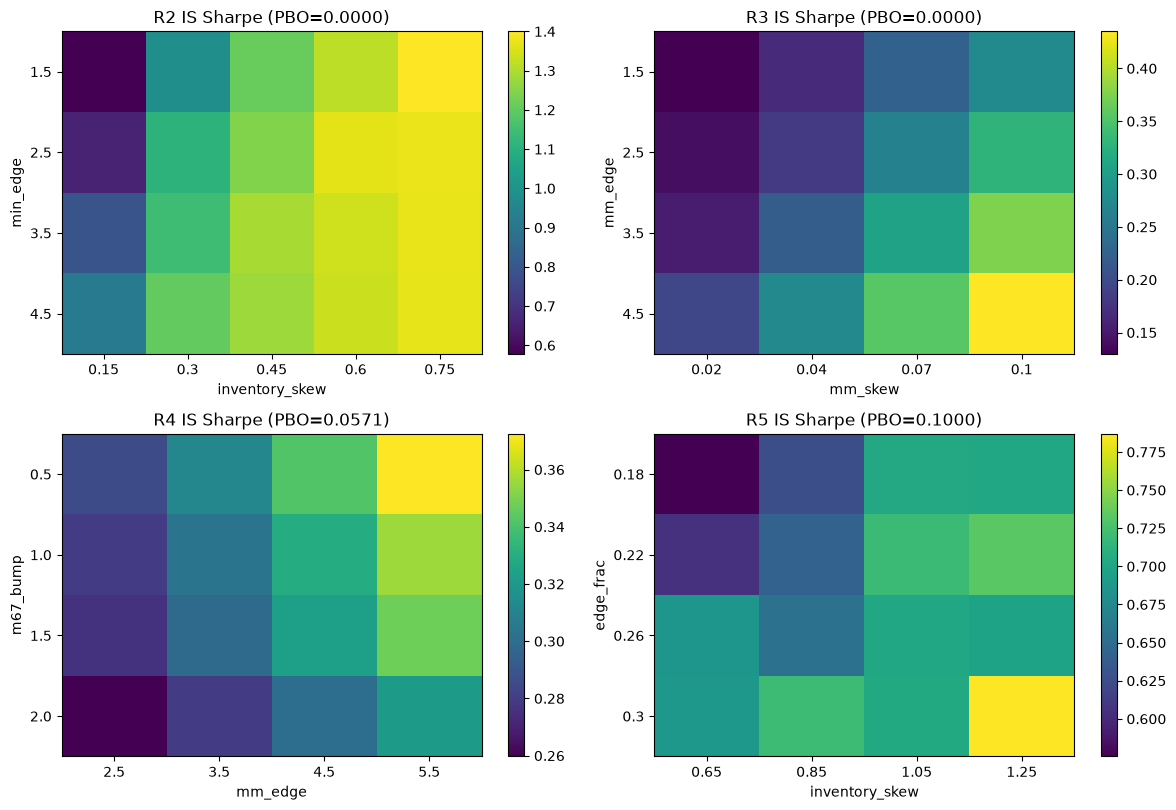

In [6]:
gates_df = pd.read_csv(root / "reports" / "tables" / "r2_to_r5_overfitting_gates.csv")
display(gates_df)

maf_df = pd.read_csv(root / "reports" / "tables" / "r2_maf_sensitivity.csv")
display(maf_df)

boot_df = pd.read_csv(root / "reports" / "tables" / "r2_to_r5_bootstrap_and_attribution.csv")
display(boot_df)

pbo_map = {int(r["round"]): float(r["cscv_pbo"]) for _, r in gates_df.iterrows()}
fig, axes = plt.subplots(2, 2, figsize=(12.0, 8.2))
grid_specs = [
    (2, "r2_sensitivity_grid.csv", "inventory_skew", "min_edge", "R2 IS Sharpe"),
    (3, "r3_sensitivity_grid.csv", "mm_skew", "mm_edge", "R3 IS Sharpe"),
    (4, "r4_sensitivity_grid.csv", "mm_edge", "m67_bump", "R4 IS Sharpe"),
    (5, "r5_sensitivity_grid.csv", "inventory_skew", "edge_frac", "R5 IS Sharpe"),
]
for idx, (rnum, fname, xcol, ycol, prefix) in enumerate(grid_specs):
    ax = axes[idx // 2, idx % 2]
    gdf = pd.read_csv(root / "reports" / "tables" / fname)
    piv = gdf.pivot(index=ycol, columns=xcol, values="is_sharpe_252")
    im = ax.imshow(piv.to_numpy(), cmap="viridis", aspect="auto")
    ax.set_xticks(range(len(piv.columns)), labels=[f"{v}" for v in piv.columns])
    ax.set_yticks(range(len(piv.index)), labels=[f"{v}" for v in piv.index])
    ax.set_xlabel(xcol)
    ax.set_ylabel(ycol)
    ax.set_title(f"{prefix} (PBO={pbo_map.get(rnum, float('nan')):.4f})")
    fig.colorbar(im, ax=ax)
fig.tight_layout()
plt.show()